# 04 · Stage 4 — Solver

Stage 4 takes the constraint run of Stage 3 (the prior $a_0$, its σ, and the rows $G$, $c$) and returns, for every year, the reconciled flows $a^*$: the one set of edges that satisfies every hard row exactly and disagrees with the prior and the soft rows as little as the σ allow.

> **What this stage assumes**
> - **A1** The prior is Gaussian with a diagonal $\Sigma_a$: no covariance between edges (Eq. 2).
> - **A3** Hard rows hold exactly; soft rows are priced by $\sigma_c^{-2}$ (Eq. 2).
> - **A4** One QP per period; no row couples two periods, enforced at build time.
> - **A13** Results are year-local: a period slice is scattered through `cols_t` before any `G @ F`.
> - Copper's choice: its QP also carries hard bands, among them the non-negativity of every flow, and is solved for the defects to a duality gap of $10^{-8}$ (ADR 0039; manuscript §3.1.6). The toy has no bands, so every row of its QP is an equality.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from pysuto._conditioning import condition_prior, condition_sigma_c
from pysuto.acc import AccountingStructure
from pysuto.cases import toy
from pysuto.diag import SolverDiag
from pysuto.registry import ConstraintRunRegistry, OptimRunRegistry

RUNS = Path("runs")
PROC = RUNS / "proc"
pd.set_option("display.width", 140)

## The run we are reading

Chapters 01–03 left a constraint run in `runs/`. Here is the one solve of Stage 4 on top of it.

In [2]:
opt_id = toy.run_stage4(RUNS)
opt_reg = OptimRunRegistry(str(PROC / "opt"))
sidecar = opt_reg.load_sidecar(opt_id)
const_id = sidecar["parents"]["upstream"]["const_run_id"]
const = ConstraintRunRegistry(str(PROC / "const")).load(const_id)
results = opt_reg.load(opt_id)
print(opt_id, "solved from", const_id)

2026-11-17 09:26:50,632 | pysuto.solver | INFO | Loading ConstraintRun 'const_20261117_092648_902c6d58' from runs/proc/const


2026-11-17 09:26:50,676 | pysuto.solver | INFO |   G shape=(500, 420)  edges=420  timesteps=5


2026-11-17 09:26:50,677 | pysuto.solver | INFO | Feasibility pre-check on 5/5 timesteps…


2026-11-17 09:26:50,693 | pysuto.solver | INFO | Feasibility pre-check passed (0.0 s).


2026-11-17 09:26:50,696 | pysuto.solver | INFO | t=2001  status=solved (Solved)  iters=0  obj=-8.4965e+03  time=0.00s  (per-t: 84 cols × 100 rows)


2026-11-17 09:26:50,699 | pysuto.solver | INFO | t=2002  status=solved (Solved)  iters=0  obj=-8.4743e+03  time=0.00s  (per-t: 84 cols × 100 rows)


... (2 outputs left out)

2026-11-17 09:26:50,707 | pysuto.solver | INFO | t=2005  status=solved (Solved)  iters=0  obj=-8.5308e+03  time=0.00s  (per-t: 84 cols × 100 rows)


2026-11-17 09:26:50,710 | pysuto.solver | INFO | OptimRun 'opt_20261117_092650_a76fbe32' persisted to runs/proc/opt


2026-11-17 09:26:50,711 | pysuto.cases.toy | INFO | stage 4: opt_20261117_092650_a76fbe32 (2001 solved, 2002 solved, 2003 solved, 2004 solved, 2005 solved)


opt_20261117_092650_a76fbe32 solved from const_20261117_092648_902c6d58


## Eq. (2) on one year

Each year is one quadratic program over the flows $a$ and the soft residuals $\varepsilon$:

$$\min_{a,\varepsilon}\; (a-a_0)^\top \Sigma_a^{-1}(a-a_0) + \varepsilon^\top \Sigma_c^{-1}\varepsilon
\quad\text{s.t.}\quad G_s a - \varepsilon = c_s,\;\; G_h a = c_h \tag{2}$$

The first term prices every edge's departure from its prior, the second prices every soft row's miss. The hard rows $G_h a = c_h$ are not priced: they must hold. (Copper's Eq. (2) has a third group, $G_b a \le c_b$, the bands; the toy has none.)

Take 2003. A year has 42 edges per valuation, so 84 unknowns. How many rows, and of which kind?

In [3]:
year = "2003"
res = results[year]
rows = np.asarray(res.rows_t)
hard = const.row_meta["is_hard"].to_numpy().astype(bool)[rows]
print(f"{year}: {len(res.cols_t)} edges (unknowns), {len(rows)} rows "
      f"= {hard.sum()} hard + {(~hard).sum()} soft")

2003: 84 edges (unknowns), 100 rows = 39 hard + 61 soft


The year's pieces, in the conditioned form the solver uses: $a_0$, $\sigma_a$, $\sigma_c$ (zero on hard rows) and the block $G$.

In [4]:
def sigma_a_of(const, res):
    _, sigma_a = condition_prior(const.a_prior_global, const.sigma_a)
    return sigma_a[np.asarray(res.cols_t)]

def sigma_c_of(const, res, t):
    sc = condition_sigma_c(np.asarray(const.timestep_data[t]["sigma_c"])[np.asarray(res.rows_t)])
    return np.where(const.row_meta["is_hard"].to_numpy().astype(bool)[np.asarray(res.rows_t)], 0.0, sc)

G = const.G[rows][:, np.asarray(res.cols_t)]
a0, sa, sc = res.a_prior, sigma_a_of(const, res), sigma_c_of(const, res, year)
print("G block", G.shape, "| σ_a from", f"{sa.min():.1e} to {sa.max():.1e}",
      "| σ_c on soft rows from", f"{sc[sc > 0].min():.1e} to {sc.max():.1e}")

G block (100, 84) | σ_a from 1.0e-06 to 1.0e+06 | σ_c on soft rows from 1.0e-03 to 4.8e+02


Evaluate Eq. (2) by hand at the solver's $a^*$: the edge term is $\sum ((a^*-a_0)/\sigma_a)^2$; the soft term is $\sum ((G_s a^*-c_s)/\sigma_c)^2$.

In [5]:
c = np.asarray(const.timestep_data[year]["c"])[rows]
edge_term = (((res.F_opt - a0) / sa) ** 2).sum()
eps = (G @ res.F_opt - c)[~hard]
soft_term = ((eps / sc[~hard]) ** 2).sum()
print(f"edge term {edge_term:.3f} + soft-row term {soft_term:.3f} = Σz² {edge_term + soft_term:.3f}")
print(f"largest hard-row miss |G_h a* − c_h| = {np.abs((G @ res.F_opt - c)[hard]).max():.1e}")

edge term 48.035 + soft-row term 0.727 = Σz² 48.762
largest hard-row miss |G_h a* − c_h| = 1.1e-13


The hard rows hold to rounding. The sum $\sum z^2$ is the year's price of reconciling.

<details><summary>Going deeper: the QP in the form Clarabel receives</summary>

The solver does not minimise Eq. (2) in $a$ directly. It substitutes $a = a_0 + d$ and solves for the defect $d$, because the cost then *is* the misfit $\sum z^2$ (ADR 0039). The objective stored in the sidecar is the cost of the original $a$-form, which differs from $\sum z^2$ by the prior-only constant $\sum (a_0/\sigma_a)^2$. The next cell checks this on 2003.

The soft residual $\varepsilon$ is eliminated, so the unknowns are the edges only; the hard rows go to Clarabel as a zero cone. Copper's bands would be a non-negative cone. The toy has none, so its QP has equality rows only.
</details>

In [6]:
const_part = ((a0 / sa) ** 2).sum()
print(f"sidecar objective {res.objective:.3f} + Σ(a₀/σ_a)² {const_part:.3f} = {res.objective + const_part:.3f}")

sidecar objective -8493.827 + Σ(a₀/σ_a)² 8542.589 = 48.762


## One Clarabel solve per year

Years are independent (A4), so Stage 4 solves one QP per year. The sidecar records status, iterations and time of each.

In [7]:
per_t = sidecar["stage_summary"]["per_timestep"]
solves = pd.DataFrame({t: {"status": v["solver_status"], "iterations": v["iterations"],
                           "solve_time_s": v["solve_time_s"], "gap_rel": v["convergence"]["gap_rel"]}
                       for t, v in per_t.items()}).T
solves

,status,iterations,solve_time_s,gap_rel
2001,solved,0,0.000773,0.0
2002,solved,0,0.00074,0.0
2003,solved,0,0.000573,0.0
2004,solved,0,0.000883,0.0
2005,solved,0,0.000579,0.0


Every year is `solved`. The iteration count is 0: a QP with equality rows only is one linear system, and Clarabel's starting point already solves it. Copper's QP has inequality rows and takes tens of iterations a year. Any status other than `solved` or `solved_inaccurate` raises an error; there is no fallback.

## The period slice

The solver returns `F_opt` for the year's 84 edges only. To use the full $G$ (all years, all edges), scatter it back through `cols_t` first (A13).

In [8]:
a_star = np.zeros(const.G.shape[1])
a_star[np.asarray(res.cols_t)] = res.F_opt
outside = np.setdiff1d(np.arange(const.G.shape[1]), res.cols_t)
print(f"full G {const.G.shape}; this year's block {G.shape}")
print(f"nonzeros of this year's rows outside its own edges: {const.G[rows][:, outside].nnz}")

full G (500, 420); this year's block (100, 84)
nonzeros of this year's rows outside its own edges: 0


No row of 2003 touches an edge of another year. That is what lets the five QPs be solved separately, and Stage 3 refuses to build a `G` where it is false.

## The residual table

Stage 4 writes no table of residuals; the toy computes one from the run. `toy.soft_residuals` lists every priced term as a z-score, largest $|z|$ first: an edge's is $(a^*-a_0)/\sigma_a$, a soft row's is $(G a^*-c)/\sigma_c$.

In [9]:
acc = AccountingStructure.load("toy", storage_dir=str(PROC / "acc"))
em = acc.edge_meta.set_index("edge_id")
table = toy.soft_residuals(RUNS)
table["edge"] = [f"{em.at[i, 'from_sector']}|{em.at[i, 'from_region']} → "
                 f"{em.at[i, 'to_sector']}|{em.at[i, 'to_region']} ({em.at[i, 'valuation']})"
                 if pd.notna(i) else "" for i in table["edge_id"]]
table.head(8)[["kind", "time", "z", "edge", "constraint_id"]]

2026-11-17 09:26:50,862 | AccountingStructure | INFO | Loading AccountingStructure 'toy' from runs/proc/acc/toy


2026-11-17 09:26:50,864 | AccountingStructure | INFO |    nodes=39  edges=420  time=2001–2005  valuations=['Gross', 'Content']  bound_exceptions=30


2026-11-17 09:26:50,866 | AccountingStructure | INFO |    user masks restored: massbal_scope


,kind,time,z,edge,constraint_id
0,edge,2003,-4.778981,Concentrate|Montara → Smelting|Portua (Gross),None
1,edge,2003,-4.031295,Concentrate|Montara → Smelting|Portua (Content),None
2,edge,2005,1.706354,Metal|Portua → Use|Portua (Content),None
3,edge,2005,1.641890,Metal|Portua → Use|Portua (Gross),None
4,edge,2004,1.536739,Metal|Isla → Use|Isla (Content),None
5,edge,2001,-1.504630,Metal|Isla → Use|Isla (Content),None
6,edge,2004,1.497774,Metal|Isla → Use|Isla (Gross),None
7,edge,2001,-1.456884,Metal|Isla → Use|Isla (Gross),None


Most terms are small. How small, by kind?

In [10]:
table.assign(absz=table["z"].abs()).groupby("kind")["absz"].describe()[["count", "50%", "max"]]

,count,50%,max
kind,,,
edge,420.0,0.114252,4.778981
row,305.0,0.015512,0.597331


## One term stands out

Look at the top of the table. A term of this size is a place where the prior and the balances cannot both be right, and the solver paid for the disagreement instead of breaking a hard row.

In [11]:
top = table[table["kind"] == "edge"].iloc[0]
same = table[(table["kind"] == "edge") & (table["time"] == top["time"])]
print(f"largest edge term: |z| = {abs(top['z']):.2f} in {top['time']}, {top['edge']}")
print(f"median |z| of the edge terms of {top['time']}: {same['z'].abs().median():.2f}")

largest edge term: |z| = 4.78 in 2003, Concentrate|Montara → Smelting|Portua (Gross)
median |z| of the edge terms of 2003: 0.11


We do not yet know whether the prior or the balances are at fault. Nothing in the pipeline can tell us; chapter 07 returns to this row with the ground truth unsealed.

## The objective, decomposed

`SolverDiag` splits $\sum z^2$ of each year into its families and shows the hard-row misses. The `year` argument chooses the years of the rocket plot, which compares the prior with $a^*$.

   SD-R-11  → runs/figs/sd_r_11_objective_decomposition.png  ✓


   SD-T-07  → runs/figs/sd_t_07_rocket.png  ✓
   ranking (edges) → runs/figs/ranking_edges.csv  ✓
   ranking (sum_rows) → runs/figs/ranking_sum_rows.csv  ✓
   ranking (soft_ratios) → runs/figs/ranking_soft_ratios.csv  ✓
   objective share by region → runs/figs/objective_share_by_region.csv  ✓
   provenance  opt_20261117_092650_a76fbe32
               └── const_20261117_092648_902c6d58
               │   └── imp_20261117_092644_c4f5fb9d
               │       ├── ?
               │       ├── ?
               │       └── ?
               → runs/figs/provenance.md  ✓


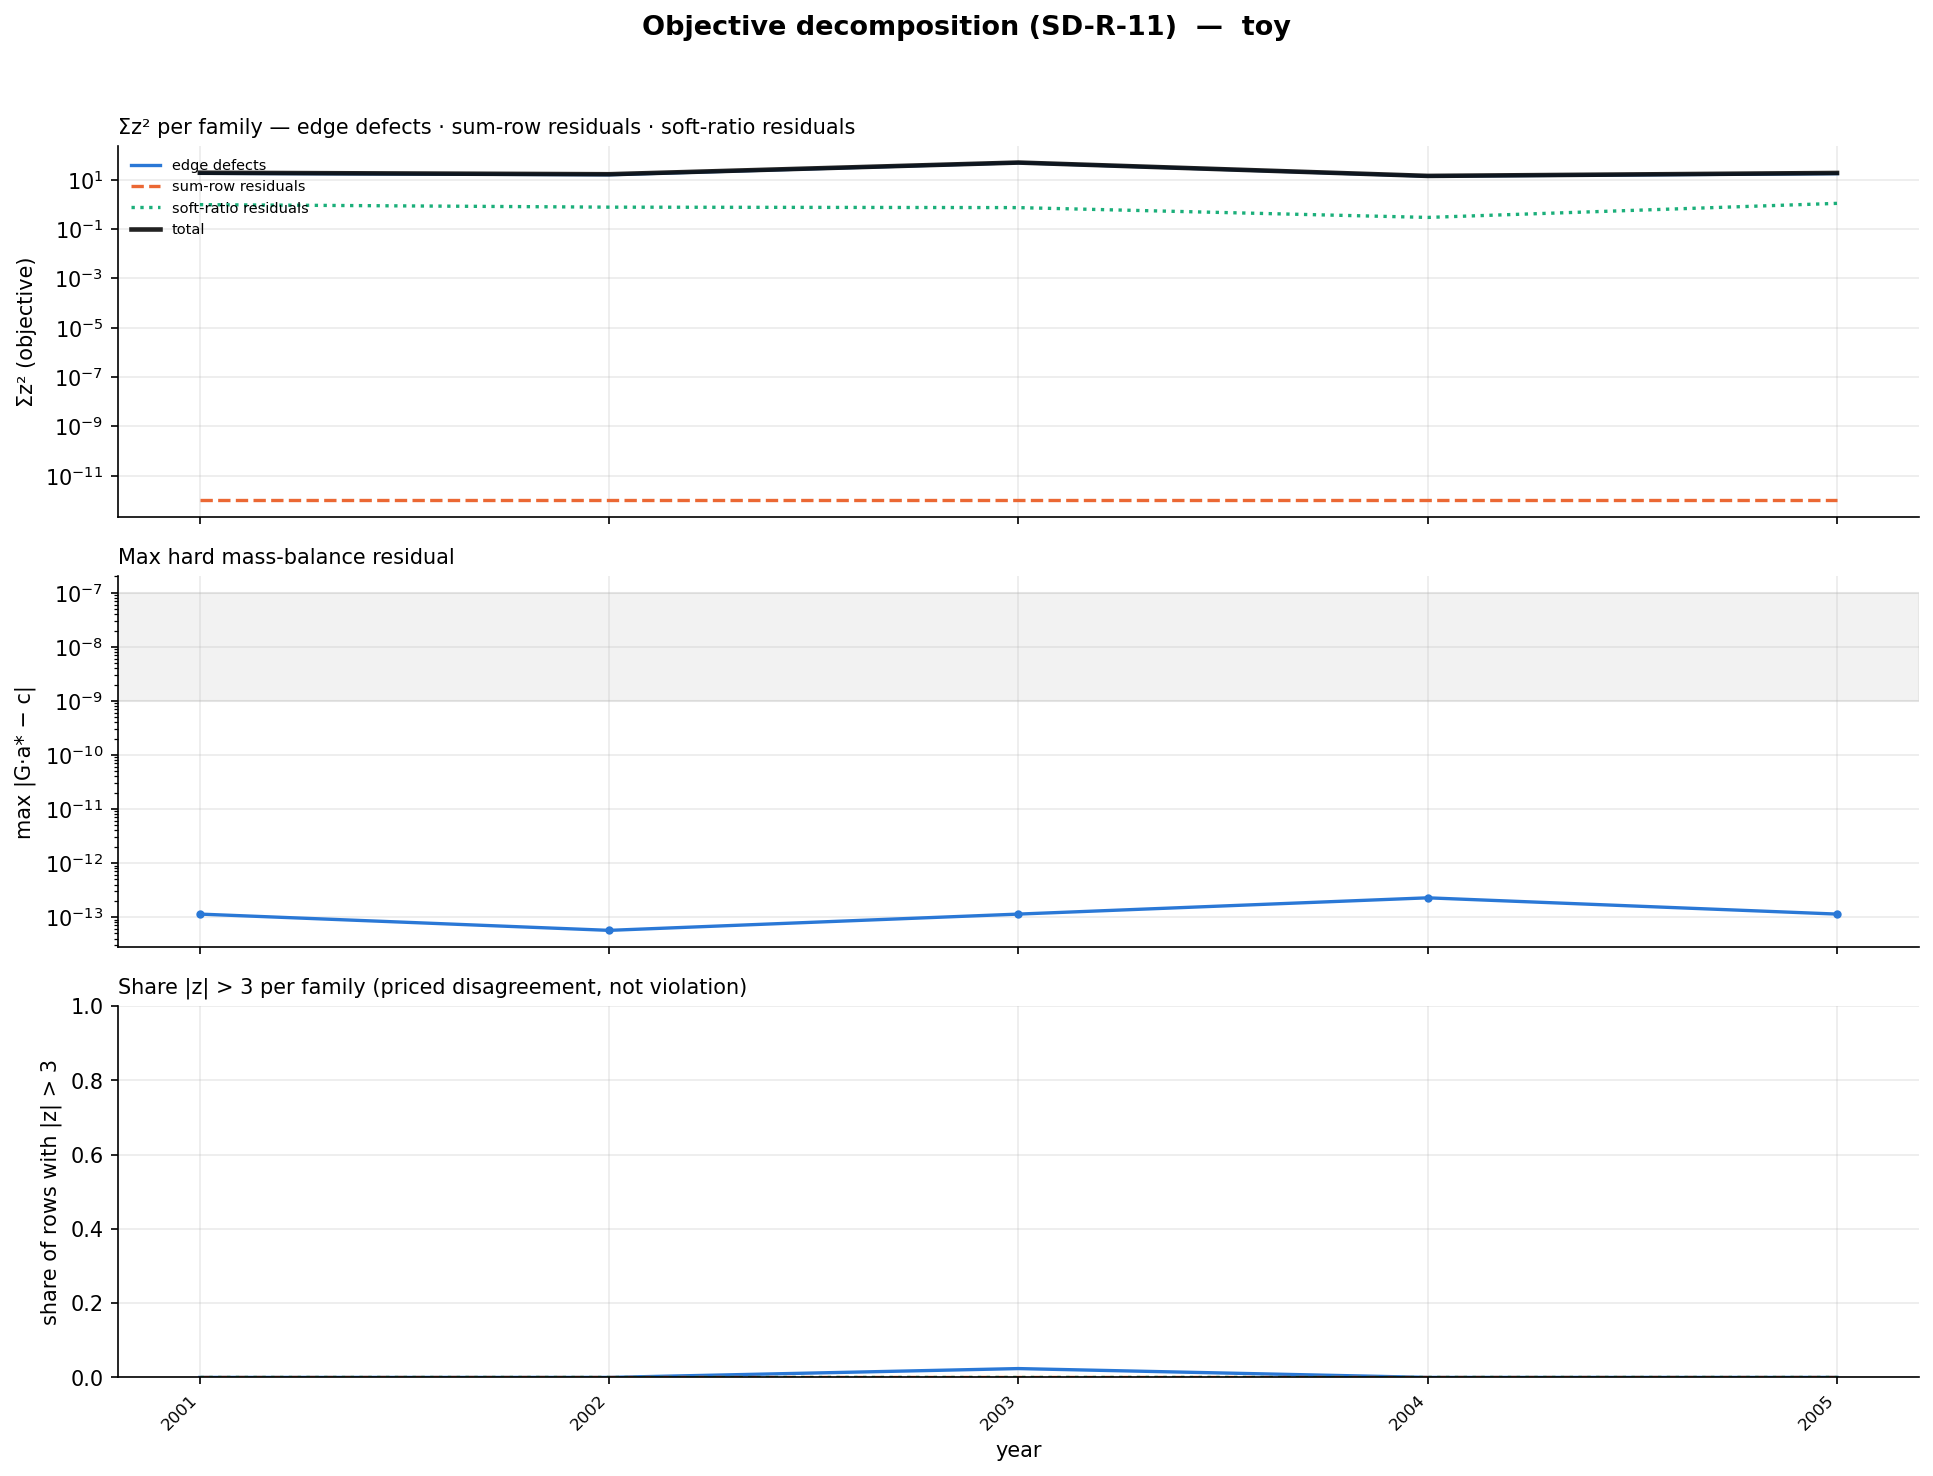

In [12]:
diag = SolverDiag.from_opt_id(opt_id, output_dir=str(PROC / "opt"), const_dir=str(PROC / "const"),
                              imp_dir=str(PROC / "imp"), label="toy", acc=acc)
paths = diag.plot(odir=str(RUNS / "figs"), plot_ids=["SD-R-11", "SD-T-07"],
                  timesteps=("2001", year, "2005"))
display(Image(str(RUNS / "figs" / "sd_r_11_objective_decomposition.png")))

Top panel: $\sum z^2$ per year and family, on a log axis. The soft rows cost far less than the edge defects, so the price of any disagreement falls on the prior edges. Middle: the hard rows hold to about $10^{-13}$ in every year. Bottom: the share of terms beyond $|z|>3$, which the toy keeps small.

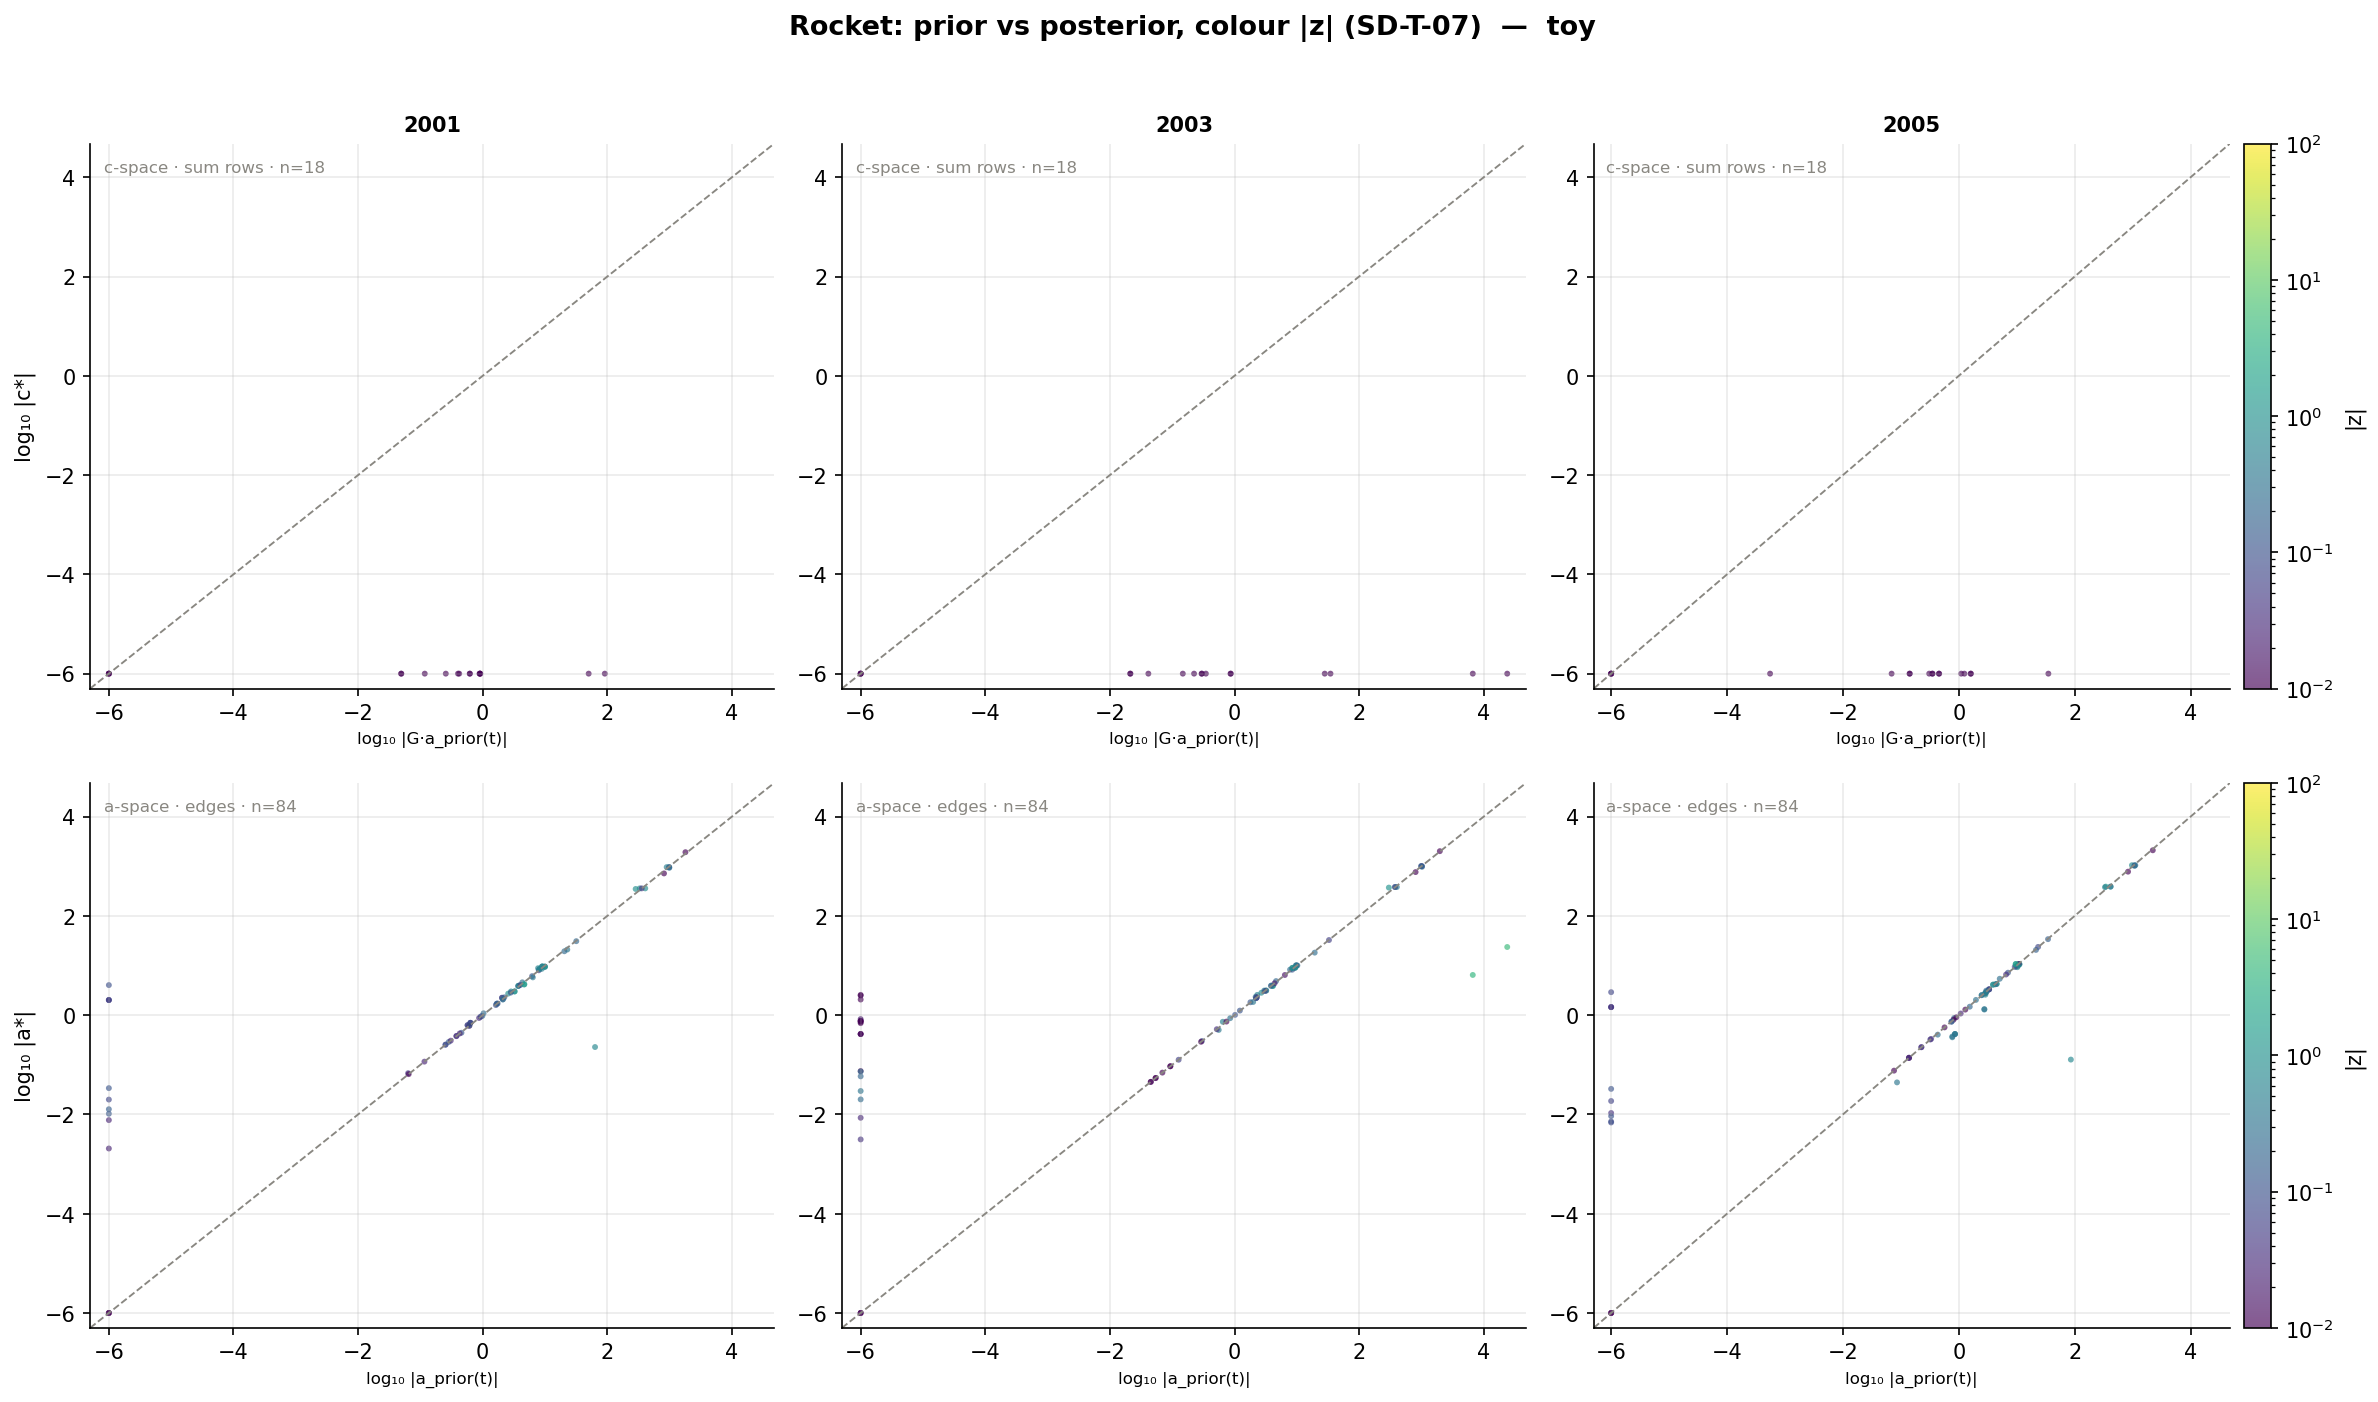

In [13]:
display(Image(str(RUNS / "figs" / "sd_t_07_rocket.png")))

Each dot is an edge, prior against $a^*$: the points sit on the diagonal except where the balances moved them.

**Exercise 4.1** — Pick the soft row of largest $|z|$. Recompute its z from the three numbers of the table below, $G a^*$, $c$ and $\sigma_c$, and check it with `toy.check_4_1`. Cover the next cell and try it first; `toy.solution("4.1")` prints the reference.

In [14]:
soft = table[table["kind"] == "row"].iloc[0]
t, k = soft["time"], int(np.flatnonzero(const.row_meta["constraint_id"] == soft["constraint_id"])[0])
r = results[t]; col = np.asarray(r.cols_t)
ga = (const.G[k][:, col] @ r.F_opt)[0]
pd.Series({"G·a*": ga, "c": const.timestep_data[t]["c"][k], "σ_c": const.timestep_data[t]["sigma_c"][k]})

G·a*    0.198995
c       0.000000
σ_c     0.333140
dtype: float64

In [15]:
z = (ga - const.timestep_data[t]["c"][k]) / const.timestep_data[t]["sigma_c"][k]
print(toy.check_4_1(RUNS, soft["constraint_id"], z))

✓ 4.1  z = +0.597


## Where this run came from

In [16]:
meta = json.loads((PROC / "opt" / opt_id / "metadata.json").read_text())
print("parents.inputs  :", meta["parents"]["inputs"])
print("parents.upstream:", meta["parents"]["upstream"])

parents.inputs  : {}
parents.upstream: {'const_run_id': 'const_20261117_092648_902c6d58'}


The opt run names its constraint run and nothing else: its inputs were fixed in Stage 3. Next: [chapter 05](05_posterior.ipynb), where $a^*$ gets an uncertainty.